# Comparaciones globales adicionales para el Capítulo III

**Tesis:** *Modelos predictivos para identificar spam en correos electrónicos*

---

## Qué genera este notebook

Tres visualizaciones globales que complementan las matrices de confusión y curvas ROC ya producidas, **sin necesidad de re-entrenar ningún modelo**. Solo lee `evaluation_folds.json`.

1. **Heatmap F1 promedio (modelos × datasets):** los 25 valores resumidos en una sola matriz. Es la figura de "resumen ejecutivo" del capítulo.
2. **Boxplot consolidado y por dataset:** muestra la dispersión del F1 entre folds. Conecta directamente con la prueba de Wilcoxon — un boxplot bien separado evidencia visualmente lo que el p-value confirma estadísticamente.
3. **Barras agrupadas con error bars (± std entre folds):** comparación numérica directa por dataset, con barras de error que muestran la variabilidad.

## Importante: estilo sin color

Conforme a las orientaciones generales de la guía de tesis, los gráficos estadísticos no usan colores para diferenciar series, sino **texturas (hatches), símbolos y escalas de grises**, garantizando legibilidad al imprimir en blanco y negro.


## Pre-requisito

Que exista `results/metrics/evaluation_folds.json`.

## 1. Setup

In [17]:
from google.colab import drive
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/spam_tesis')
RESULTS_DIR  = PROJECT_ROOT / 'results'
METRICS_DIR  = RESULTS_DIR / 'metrics'
FIGURES_DIR  = RESULTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Estilo academico, sin color
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

print(f'[OK] Drive montado.')
print(f'[OK] METRICS_DIR : {METRICS_DIR}')
print(f'[OK] FIGURES_DIR : {FIGURES_DIR}')

[OK] Drive montado.
[OK] METRICS_DIR : /content/drive/MyDrive/spam_tesis/results/metrics
[OK] FIGURES_DIR : /content/drive/MyDrive/spam_tesis/results/figures


## 2. Carga de los F1 por fold

In [18]:
folds_path = METRICS_DIR / 'evaluation_folds.json'

if not folds_path.exists():
    raise FileNotFoundError(
        f'No existe {folds_path}. Ejecuta primero el parche grande para generarlo.'
    )

with open(folds_path, 'r', encoding='utf-8') as f:
    fold_results = json.load(f)

# Orden canonico de modelos (mantiene consistencia entre figuras)
MODEL_ORDER = ['naive_bayes', 'svm_rbf', 'random_forest', 'soft_voting', 'stacking']
MODEL_LABELS = {
    'naive_bayes':   'Naïve Bayes',
    'svm_rbf':       'SVM (RBF)',
    'random_forest': 'Random Forest',
    'soft_voting':   'Soft Voting',
    'stacking':      'Stacking',
}

DATASETS = list(fold_results.keys())
MODELS   = [m for m in MODEL_ORDER if any(m in fold_results[d] and fold_results[d][m] for d in DATASETS)]

print(f'[OK] Datasets ({len(DATASETS)}): {DATASETS}')
print(f'[OK] Modelos  ({len(MODELS)}): {MODELS}')

[OK] Datasets (5): ['sms_spam', 'spambase', 'youtube_shakira', 'trspam', 'spam_ham_email']
[OK] Modelos  (5): ['naive_bayes', 'svm_rbf', 'random_forest', 'soft_voting', 'stacking']


## 3. Construcción de matrices base

- `mean_matrix[i, j]` = F1 medio del modelo *i* en el dataset *j* (entre folds).
- `std_matrix[i, j]`  = desviación estándar del F1 del modelo *i* en el dataset *j*.
- `long_df`           = un registro por (dataset, modelo, fold). Útil para boxplots.

In [19]:
n_models   = len(MODELS)
n_datasets = len(DATASETS)

mean_matrix = np.full((n_models, n_datasets), np.nan)
std_matrix  = np.full((n_models, n_datasets), np.nan)

long_records = []

for j, ds in enumerate(DATASETS):
    for i, m in enumerate(MODELS):
        scores = fold_results.get(ds, {}).get(m, [])
        if not scores:
            continue
        arr = np.asarray(scores, dtype=float)
        mean_matrix[i, j] = arr.mean()
        std_matrix[i, j]  = arr.std(ddof=1) if len(arr) > 1 else 0.0
        for k, s in enumerate(arr):
            long_records.append({
                'dataset': ds,
                'model':   m,
                'model_label': MODEL_LABELS[m],
                'fold':    k,
                'f1':      float(s),
            })

long_df = pd.DataFrame(long_records)

# Persistencia para auditoria
long_df.to_csv(METRICS_DIR / 'evaluation_long.csv', index=False)
print(f'[OK] {METRICS_DIR / "evaluation_long.csv"} guardado ({len(long_df)} filas).')

# Vista rapida
df_means = pd.DataFrame(mean_matrix, index=[MODEL_LABELS[m] for m in MODELS], columns=DATASETS)
print('\nF1 promedio (modelos x datasets):')
print(df_means.round(4).to_string())

[OK] /content/drive/MyDrive/spam_tesis/results/metrics/evaluation_long.csv guardado (120 filas).

F1 promedio (modelos x datasets):
               sms_spam  spambase  youtube_shakira  trspam  spam_ham_email
Naïve Bayes      0.9511       NaN           0.9038  0.9354          0.9719
SVM (RBF)        0.9448    0.9328           0.9159  0.9289          0.9855
Random Forest    0.9240    0.9506           0.9155  0.8943          0.9681
Soft Voting      0.9557    0.9471           0.9195  0.9416          0.9829
Stacking         0.9585    0.9537           0.9274  0.9335          0.9847


## 4. Comparación 1 — Heatmap F1 promedio (modelos × datasets)

Una sola figura que resume los 25 experimentos. Lectura rápida: filas oscuras → modelo fuerte; columnas oscuras → dataset "fácil".

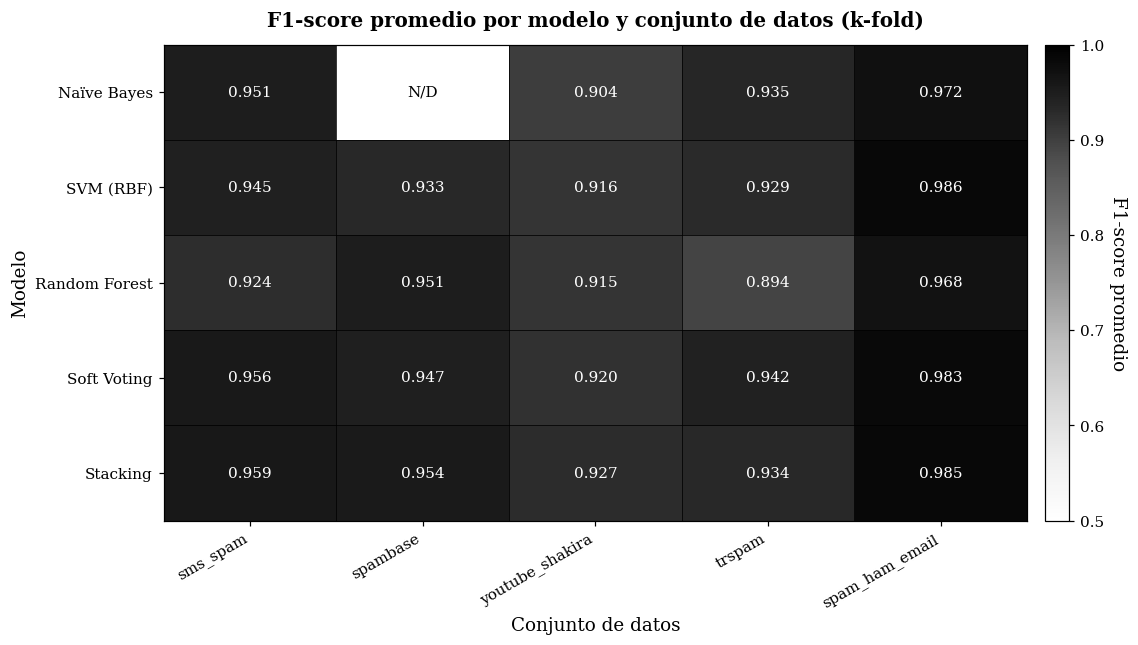

[OK] Guardado: fig_heatmap_f1_modelo_dataset.png


In [20]:
fig, ax = plt.subplots(figsize=(1.6 * n_datasets + 2.5, 0.8 * n_models + 2))

# Escala de grises: oscuro = mejor F1
im = ax.imshow(mean_matrix, cmap='Greys', vmin=0.5, vmax=1.0, aspect='auto')

ax.set_xticks(np.arange(n_datasets))
ax.set_yticks(np.arange(n_models))
ax.set_xticklabels(DATASETS, rotation=30, ha='right')
ax.set_yticklabels([MODEL_LABELS[m] for m in MODELS])

# Anotaciones con contraste automatico (texto blanco si el fondo es oscuro)
for i in range(n_models):
    for j in range(n_datasets):
        v = mean_matrix[i, j]
        if np.isnan(v):
            ax.text(j, i, 'N/D', ha='center', va='center', fontsize=10, color='black')
        else:
            color = 'white' if v > 0.78 else 'black'
            ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=10, color=color)

# Bordes de celda
ax.set_xticks(np.arange(-0.5, n_datasets, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_models, 1), minor=True)
ax.grid(which='minor', color='black', linewidth=0.5)
ax.tick_params(which='minor', length=0)

cbar = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('F1-score promedio', rotation=270, labelpad=15)

ax.set_title('F1-score promedio por modelo y conjunto de datos (k-fold)',
             pad=12, fontweight='bold')
ax.set_xlabel('Conjunto de datos')
ax.set_ylabel('Modelo')

fig.tight_layout()
out_png = FIGURES_DIR / 'fig_heatmap_f1_modelo_dataset.png'
fig.savefig(out_png)
plt.show()

print(f'[OK] Guardado: {out_png.name}')


## 5. Comparación 2 — Boxplot consolidado y por dataset

**Panel superior:** distribución del F1 de cada modelo agregando todos los folds de todos los datasets. Permite ver qué modelo es **globalmente** más estable.

**Panel inferior:** un boxplot por dataset, con los 5 modelos. Permite ver dónde un modelo gana o pierde por dispersión, no solo por media.

Las cajas usan **rellenos con texturas** (hatches) en lugar de color para que sigan siendo distinguibles al imprimir en B/N.

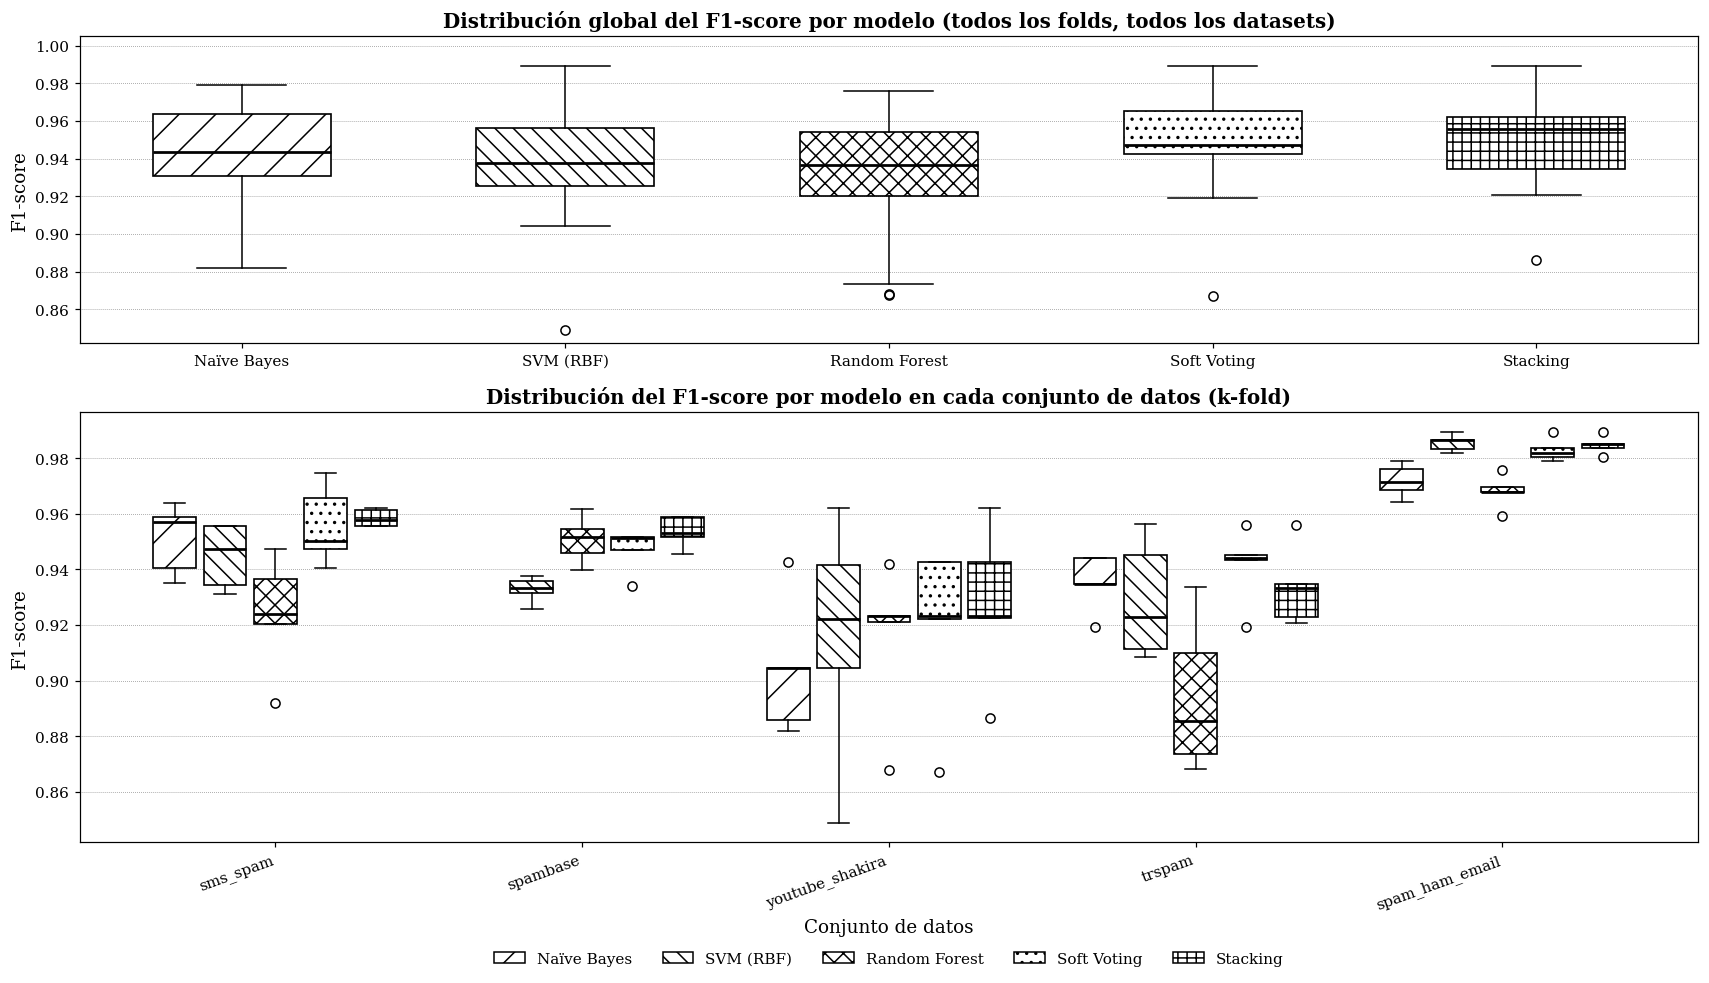

[OK] Guardado: fig_boxplot_f1_global_y_por_dataset.png


In [21]:
# Patrones de relleno por modelo (uno por modelo, consistente entre figuras)
HATCHES = ['/', '\\\\', 'xx', '..', '++']
hatch_map = {m: HATCHES[i % len(HATCHES)] for i, m in enumerate(MODELS)}

def _style_box(bp, models):
    """Aplica hatch + bordes negros a cada caja."""
    for patch, m in zip(bp['boxes'], models):
        patch.set_facecolor('white')
        patch.set_edgecolor('black')
        patch.set_linewidth(1.1)
        patch.set_hatch(hatch_map[m])
    for element in ('whiskers', 'caps', 'fliers'):
        for line in bp[element]:
            line.set_color('black')
            line.set_linewidth(1.0)
    for median in bp['medians']:
        median.set_color('black')
        median.set_linewidth(1.8)

fig, axes = plt.subplots(2, 1, figsize=(max(10, 1.4 * n_datasets * n_models / 3 + 4), 9),
                         gridspec_kw={'height_ratios': [1, 1.4]})

# --- Panel superior: boxplot global por modelo ---
ax0 = axes[0]
data_global = [long_df.loc[long_df['model'] == m, 'f1'].values for m in MODELS]
bp0 = ax0.boxplot(data_global, patch_artist=True, widths=0.55,
                  labels=[MODEL_LABELS[m] for m in MODELS])
_style_box(bp0, MODELS)

ax0.set_ylabel('F1-score')
ax0.set_title('Distribución global del F1-score por modelo (todos los folds, todos los datasets)',
              fontweight='bold')
ax0.grid(axis='y', linestyle=':', linewidth=0.5, color='gray')
ax0.set_ylim(top=min(1.005, np.nanmax(mean_matrix) + 0.05))

# --- Panel inferior: boxplot por dataset, agrupado por modelo ---
ax1 = axes[1]
group_width = 0.82
box_width   = group_width / n_models
positions   = np.arange(n_datasets)

for i, m in enumerate(MODELS):
    offset = (i - (n_models - 1) / 2) * box_width
    pos = positions + offset
    data_m = [long_df[(long_df['model'] == m) & (long_df['dataset'] == ds)]['f1'].values
              for ds in DATASETS]
    bp = ax1.boxplot(data_m, positions=pos, widths=box_width * 0.85,
                     patch_artist=True, manage_ticks=False)
    _style_box(bp, [m] * n_datasets)

ax1.set_xticks(positions)
ax1.set_xticklabels(DATASETS, rotation=20, ha='right')
ax1.set_ylabel('F1-score')
ax1.set_xlabel('Conjunto de datos')
ax1.set_title('Distribución del F1-score por modelo en cada conjunto de datos (k-fold)',
              fontweight='bold')
ax1.grid(axis='y', linestyle=':', linewidth=0.5, color='gray')

# Leyenda manual con los hatches
legend_handles = [Patch(facecolor='white', edgecolor='black', hatch=hatch_map[m],
                        label=MODEL_LABELS[m]) for m in MODELS]
ax1.legend(handles=legend_handles, loc='lower center', bbox_to_anchor=(0.5, -0.32),
           ncol=min(n_models, 5), frameon=False)

fig.tight_layout()
out_png = FIGURES_DIR / 'fig_boxplot_f1_global_y_por_dataset.png'
fig.savefig(out_png)
plt.show()
print(f'[OK] Guardado: {out_png.name}')


## 6. Comparación 3 — Barras agrupadas con error bars

Comparación numérica directa: la altura de cada barra es el F1 promedio entre folds y el error bar es la desviación estándar entre folds. Es la figura que el tribunal busca para responder de un vistazo a *"¿qué modelo gana en cada dataset y con cuánta variabilidad?"*.

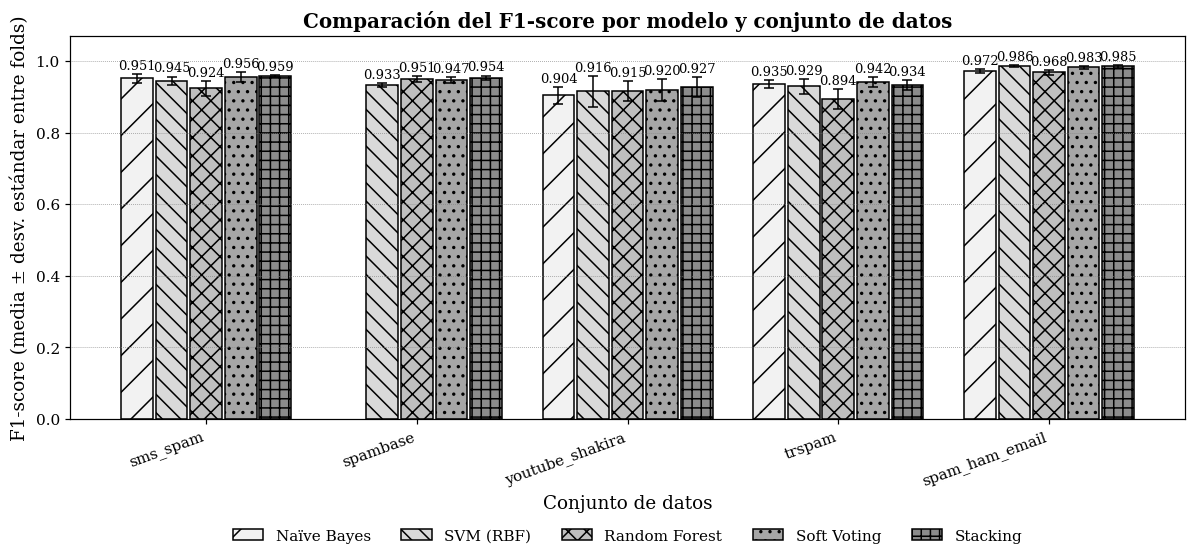

[OK] Guardado: fig_barras_f1_modelo_dataset.png


In [22]:
fig, ax = plt.subplots(figsize=(max(10, 1.6 * n_datasets + 3), 5.5))

group_width = 0.82
bar_width   = group_width / n_models
x_centers   = np.arange(n_datasets)

# Tonalidades de gris distintas por modelo (complemento al hatch)
GRAYS = np.linspace(0.95, 0.55, n_models)

for i, m in enumerate(MODELS):
    offset = (i - (n_models - 1) / 2) * bar_width
    means = mean_matrix[i, :]
    stds  = std_matrix[i, :]
    bars = ax.bar(x_centers + offset, means, bar_width * 0.92,
                  yerr=stds, capsize=3,
                  facecolor=str(GRAYS[i]), edgecolor='black', linewidth=1.0,
                  hatch=hatch_map[m], label=MODEL_LABELS[m],
                  error_kw={'elinewidth': 1.0, 'ecolor': 'black'})
    # Etiqueta numerica encima de cada barra
    for rect, v in zip(bars, means):
        if not np.isnan(v):
            ax.text(rect.get_x() + rect.get_width() / 2,
                    rect.get_height() + (stds[list(means).index(v)] if not np.isnan(stds[list(means).index(v)]) else 0) + 0.005,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=8.5, rotation=0)

ax.set_xticks(x_centers)
ax.set_xticklabels(DATASETS, rotation=20, ha='right')
ax.set_ylabel('F1-score (media ± desv. estándar entre folds)')
ax.set_xlabel('Conjunto de datos')
ax.set_title('Comparación del F1-score por modelo y conjunto de datos',
             fontweight='bold')
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='gray')
ax.set_ylim(0, min(1.08, np.nanmax(mean_matrix + std_matrix) + 0.08))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.36),
          ncol=min(n_models, 5), frameon=False)

fig.tight_layout()
out_png = FIGURES_DIR / 'fig_barras_f1_modelo_dataset.png'
fig.savefig(out_png)
plt.show()
print(f'[OK] Guardado: {out_png.name}')


## 7. Tabla resumen para el Capítulo III

Tabla numérica que acompaña a las tres figuras anteriores. Lista para insertar en el capítulo.

In [23]:
# Construye una tabla con F1 medio +/- std por celda
rows = []
for i, m in enumerate(MODELS):
    row = {'Modelo': MODEL_LABELS[m]}
    for j, ds in enumerate(DATASETS):
        mu = mean_matrix[i, j]
        sd = std_matrix[i, j]
        if np.isnan(mu):
            row[ds] = 'N/D'
        else:
            row[ds] = f'{mu:.3f} ± {sd:.3f}'
    rows.append(row)

df_resumen = pd.DataFrame(rows)

# Marca el mejor modelo por dataset (para uso en el texto del capitulo)
best_per_ds = {ds: MODEL_LABELS[MODELS[int(np.nanargmax(mean_matrix[:, j]))]]
               for j, ds in enumerate(DATASETS)}

out_csv = METRICS_DIR / 'evaluation_resumen_capitulo3.csv'
df_resumen.to_csv(out_csv, index=False)

print('Tabla resumen — F1 medio ± desv. estándar (entre folds):')
print('=' * 110)
print(df_resumen.to_string(index=False))
print('=' * 110)

print('\nMejor modelo por dataset:')
for ds, model in best_per_ds.items():
    print(f'  {ds:<25} -> {model}')

print(f'\n[OK] Tabla guardada en: {out_csv}')

Tabla resumen — F1 medio ± desv. estándar (entre folds):
       Modelo      sms_spam      spambase youtube_shakira        trspam spam_ham_email
  Naïve Bayes 0.951 ± 0.013           N/D   0.904 ± 0.024 0.935 ± 0.010  0.972 ± 0.006
    SVM (RBF) 0.945 ± 0.012 0.933 ± 0.005   0.916 ± 0.043 0.929 ± 0.021  0.986 ± 0.003
Random Forest 0.924 ± 0.021 0.951 ± 0.008   0.915 ± 0.028 0.894 ± 0.027  0.968 ± 0.006
  Soft Voting 0.956 ± 0.014 0.947 ± 0.008   0.920 ± 0.031 0.942 ± 0.013  0.983 ± 0.004
     Stacking 0.959 ± 0.003 0.954 ± 0.006   0.927 ± 0.028 0.934 ± 0.014  0.985 ± 0.003

Mejor modelo por dataset:
  sms_spam                  -> Stacking
  spambase                  -> Stacking
  youtube_shakira           -> Stacking
  trspam                    -> Soft Voting
  spam_ham_email            -> SVM (RBF)

[OK] Tabla guardada en: /content/drive/MyDrive/spam_tesis/results/metrics/evaluation_resumen_capitulo3.csv


## 8. Cierre

In [24]:
print('=' * 70)
print('COMPARACIONES GLOBALES COMPLETADAS')
print('=' * 70)
print(f'\nFiguras generadas en: {FIGURES_DIR}')
for f in sorted(FIGURES_DIR.glob('fig_*')):
    print(f'  - {f.name}')
print(f'\nTablas auxiliares:')
print(f'  - {METRICS_DIR / "evaluation_long.csv"}')
print(f'  - {METRICS_DIR / "evaluation_resumen_capitulo3.csv"}')
print('\nCada figura está disponible en PNG (300 dpi)')
print('lista para insertar en la memoria escrita.')

COMPARACIONES GLOBALES COMPLETADAS

Figuras generadas en: /content/drive/MyDrive/spam_tesis/results/figures
  - fig_barras_f1_modelo_dataset.png
  - fig_boxplot_f1_global_y_por_dataset.png
  - fig_heatmap_f1_modelo_dataset.png

Tablas auxiliares:
  - /content/drive/MyDrive/spam_tesis/results/metrics/evaluation_long.csv
  - /content/drive/MyDrive/spam_tesis/results/metrics/evaluation_resumen_capitulo3.csv

Cada figura está disponible en PNG (300 dpi)
lista para insertar en la memoria escrita.
